1. IMPORTANDO PACOTES

In [ ]:
# Instalar o pacote necessário
install.packages("cluster")

# Carregar o pacote
library(cluster)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



2. IMPORTANDO BASE DE DADOS

In [ ]:
dados <- read.csv(
  arquivo,
  header = TRUE,
  sep = ",",
  stringsAsFactors = FALSE
)

# Conferir dimensões
dim(dados)

[1] 1097014      16

3. SELECIONANDO SOMENTE CARGAS CONTERIZADAS

In [ ]:
dados_reg <- subset(
  dados,
  NATUREZA_CARGA == "CARGA CONTEINERIZADA"
)

# Conferir a quantidade de registros
dim(dados_reg)

[1] 978320     16

4. PREPARANDO AS VARIÁVEIS

In [ ]:
# Converter as variáveis para números
variaveis <- c(
  "TOTAL_TONELADAS",
  "TOTAL_TEU",
  "TOTAL_UNID",
  "ANO",
  "MES"
)

dados_reg[variaveis] <- lapply(
  dados_reg[variaveis],
  function(x) {
    as.numeric(gsub(",", ".", as.character(x), fixed = TRUE))
  }
)

# Manter somente registros completos e válidos
dados_reg <- dados_reg[
  complete.cases(dados_reg[, variaveis]) &
    dados_reg$TOTAL_TONELADAS >= 0 &
    dados_reg$TOTAL_TEU >= 0 &
    dados_reg$TOTAL_UNID >= 0,
  variaveis
]

# Conferir o resultado
dim(dados_reg)
summary(dados_reg)

[1] 978320      5

 TOTAL_TONELADAS       TOTAL_TEU         TOTAL_UNID           ANO      
 Min.   :    1.158   Min.   :   1.00   Min.   :   1.00   Min.   :2005  
 1st Qu.:   37.400   1st Qu.:   3.00   1st Qu.:   2.00   1st Qu.:2010  
 Median :  145.250   Median :  11.00   Median :   8.00   Median :2016  
 Mean   :  892.874   Mean   :  82.67   Mean   :  51.54   Mean   :2016  
 3rd Qu.:  585.211   3rd Qu.:  51.00   3rd Qu.:  34.00   3rd Qu.:2021  
 Max.   :58706.000   Max.   :5445.00   Max.   :3222.00   Max.   :2026  
      MES        
 Min.   : 1.000  
 1st Qu.: 4.000  
 Median : 7.000  
 Mean   : 6.534  
 3rd Qu.:10.000  
 Max.   :12.000  

5. SEPARANDO AS RESPOSTAS DOS PREDITORES

In [ ]:
# Variável resposta (Y)
y <- dados_reg$TOTAL_TONELADAS

# Preditores (X)
X <- dados_reg[, c(
  "TOTAL_TEU",
  "TOTAL_UNID",
  "ANO",
  "MES"
)]

# Conferir
head(X)
head(y)

,TOTAL_TEU,TOTAL_UNID,ANO,MES
,<dbl>,<dbl>,<dbl>,<dbl>
1,92,76,2012,11
2,28,14,2012,10
3,598,335,2012,10
4,30,24,2012,11
5,317,227,2012,11
6,14,14,2012,11


[1] 1504.855  190.550 5631.350  596.370 4601.841  276.870

6. SEPARANDO UMA AMOSTRAS DE 2 MIL REGISTROS

In [ ]:
# Fixar a semente para reproduzir o resultado
set.seed(1)

# Selecionar 2.000 observações
amostra_id <- sample(
  seq_len(nrow(dados_reg)),
  2000
)

# Criar a amostra
d <- dados_reg[amostra_id, ]

# Conferir
dim(d)

[1] 2000    5

7. PREPARANDO OS DADOS PARA O PCA E O K-MEANS

In [ ]:
# Transformar as variáveis com maior dispersão
X <- data.frame(
  TOTAL_TEU = log1p(d$TOTAL_TEU),
  TOTAL_UNID = log1p(d$TOTAL_UNID),
  ANO = d$ANO,
  MES = d$MES
)

# Padronizar os preditores
Z <- scale(X)

# Calcular as distâncias entre as observações
D <- dist(Z)

8. APLICANDO O PCA

In [ ]:
# Aplicar PCA
pca <- prcomp(X, scale. = TRUE)

# Mostrar a variância explicada
summary(pca)

# Mostrar os pesos das variáveis
round(pca$rotation[, 1:2], 3)

Importance of components:
                         PC1    PC2    PC3     PC4
Standard deviation     1.416 1.0004 0.9922 0.10380
Proportion of Variance 0.501 0.2502 0.2461 0.00269
Cumulative Proportion  0.501 0.7512 0.9973 1.00000

,PC1,PC2
TOTAL_TEU,0.702,0.013
TOTAL_UNID,0.702,0.016
ANO,0.120,-0.220
MES,-0.007,-0.975


9. ESCOLHENDO A QUANTIDADE DE GRUPOS(K) USANDO A SILHUETA

In [ ]:
# Quantidades de grupos que serão testadas
ks <- 2:8

# Calcular a silhueta para cada K
set.seed(1)

S <- sapply(ks, function(k) {

  modelo <- kmeans(
    Z,
    centers = k,
    nstart = 25
  )

  sil <- silhouette(
    modelo$cluster,
    D
  )

  mean(sil[, 3])
})

# Mostrar os resultados
data.frame(
  K = ks,
  Silhueta = round(S, 4)
)

K,Silhueta
<int>,<dbl>
2,0.3308
3,0.2680
4,0.2707
5,0.2688
6,0.2718
7,0.2682
8,0.2728


10. ESCOLHENDO O MELHOR K E EXECUTANDO O K-MEANS

In [ ]:
# Identificar o K com maior silhueta
K <- ks[which.max(S)]

# Mostrar o K escolhido
K

# Executar o agrupamento final
set.seed(1)

km <- kmeans(
  Z,
  centers = K,
  nstart = 25
)

# Adicionar os grupos à amostra
d$grupo <- factor(km$cluster)

# Conferir a quantidade de operações por grupo
table(d$grupo)

[1] 2


   1    2 
 715 1285 

11. APRESENTANDO O CENTRO DOS GRUPOS NAS UNIDADES ORIGINAIS

In [ ]:
# Calcular os centros nas unidades originais
centros <- aggregate(
  d[, c("TOTAL_TEU", "TOTAL_UNID", "ANO", "MES")],
  by = list(grupo = d$grupo),
  FUN = mean
)

# Arredondar somente as colunas numéricas
centros[, -1] <- round(centros[, -1], 2)

# Mostrar os centros
centros

grupo,TOTAL_TEU,TOTAL_UNID,ANO,MES
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
1,207.81,126.90,2016.31,6.42
2,6.80,4.76,2015.16,6.55


12. CRIANDO O GRÁFICO PCA - PC1 X PC2

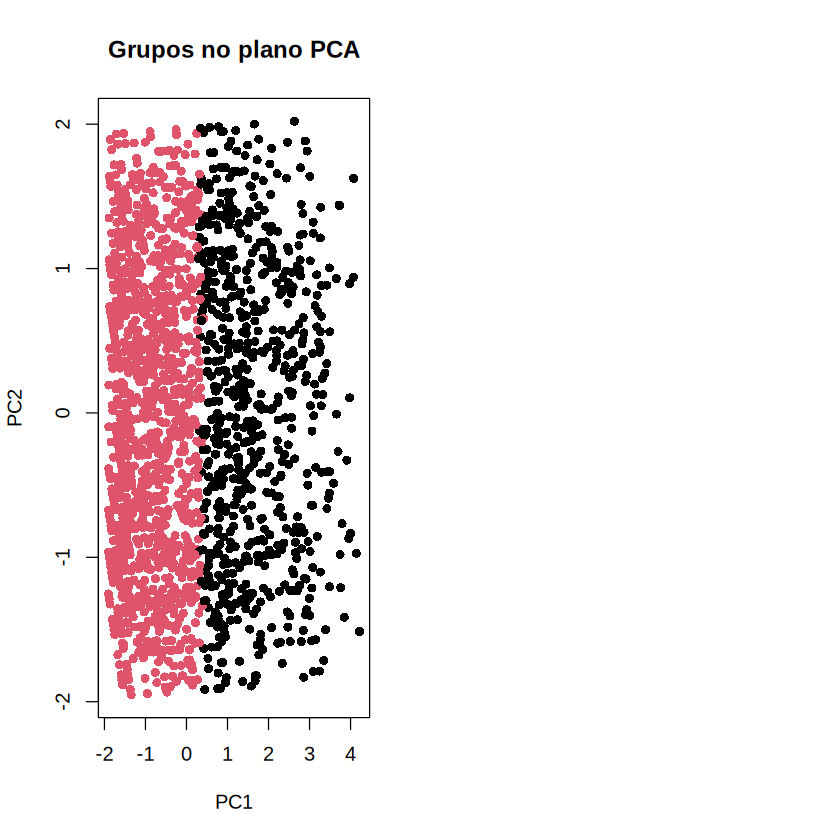

In [ ]:
# Configurar a área do gráfico
par(mfrow = c(1, 2))

# Gráfico PCA
plot(
  pca$x[, 1:2],
  col = km$cluster,
  pch = 16,
  xlab = "PC1",
  ylab = "PC2",
  main = "Grupos no plano PCA"
)

13. CRIANDO O GRÁFICO DE TONELADAS POR GRUPO

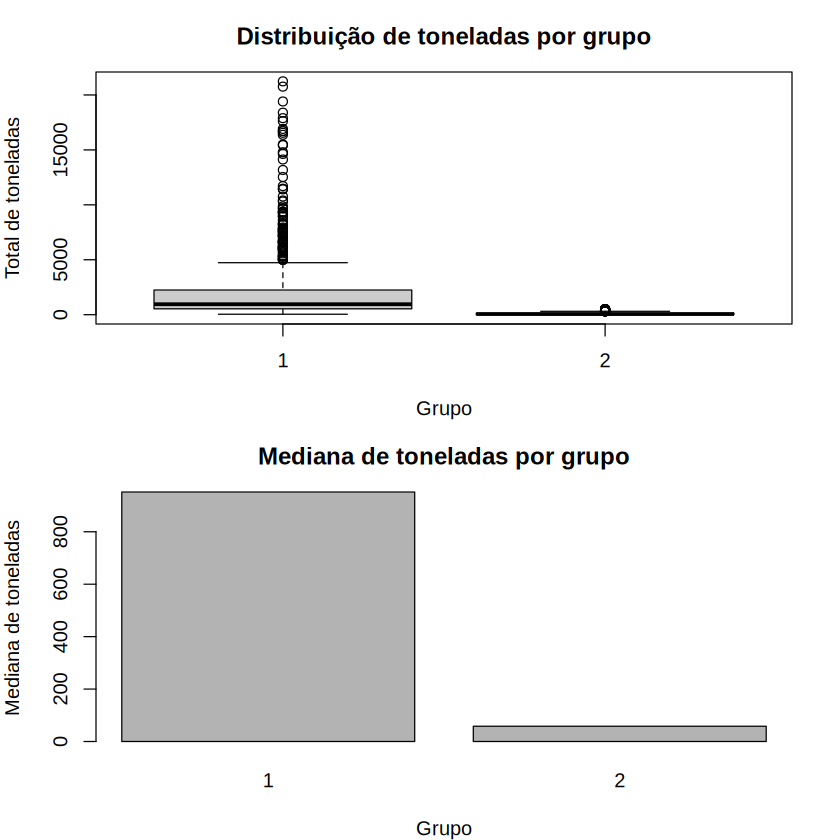

In [ ]:
# Organizar os gráficos um abaixo do outro
par(mfrow = c(2, 1), mar = c(4, 4, 3, 2))

# GRÁFICO 1 - Boxplot
boxplot(
  TOTAL_TONELADAS ~ grupo,
  data = d,
  xlab = "Grupo",
  ylab = "Total de toneladas",
  main = "Distribuição de toneladas por grupo",
  col = "gray80"
)

# Espaço entre os gráficos
par(mar = c(4, 4, 3, 2))

# Calcular a mediana de toneladas por grupo
medianas <- aggregate(
  TOTAL_TONELADAS ~ grupo,
  data = d,
  FUN = median
)

# GRÁFICO 2 - Barras (sem boxplot)
barplot(
  medianas$TOTAL_TONELADAS,
  names.arg = medianas$grupo,
  xlab = "Grupo",
  ylab = "Mediana de toneladas",
  main = "Mediana de toneladas por grupo",
  col = "gray70"
)

# Voltar à configuração normal
par(mfrow = c(1, 1))

14. CALCULANDO A MÉDIA DE TONELADAS POR GRUPO

In [ ]:
# Média de toneladas por grupo
medias_grupos <- aggregate(
  TOTAL_TONELADAS ~ grupo,
  data = d,
  FUN = mean
)

# Mediana de toneladas por grupo
medianas_grupos <- aggregate(
  TOTAL_TONELADAS ~ grupo,
  data = d,
  FUN = median
)

medias_grupos
medianas_grupos

grupo,TOTAL_TONELADAS
<fct>,<dbl>
1,2179.359
2,100.219


grupo,TOTAL_TONELADAS
<fct>,<dbl>
1,951.652
2,58.186


15. O GRUPO VIRA PREDITOR?

In [ ]:
# Modelo sem o grupo
modelo_sem_grupo <- lm(
  log1p(TOTAL_TONELADAS) ~
    log1p(TOTAL_TEU) +
    log1p(TOTAL_UNID) +
    ANO +
    MES,
  data = d
)

# Modelo com o grupo
modelo_com_grupo <- lm(
  log1p(TOTAL_TONELADAS) ~
    log1p(TOTAL_TEU) +
    log1p(TOTAL_UNID) +
    ANO +
    MES +
    grupo,
  data = d
)

# Comparar o R²
data.frame(
  Modelo = c("Sem grupo", "Com grupo"),
  R2 = c(
    summary(modelo_sem_grupo)$r.squared,
    summary(modelo_com_grupo)$r.squared
  )
)

Modelo,R2
<chr>,<dbl>
Sem grupo,0.8467433
Com grupo,0.8468918


16. CONCLUSÃO


A análise de 2.000 registros identificou dois grupos de operações: grandes e pequenas. Os resultados mostraram que TOTAL_TEU e TOTAL_UNID estão relacionados ao tamanho das operações e à quantidade de toneladas movimentadas.

As operações maiores movimentaram, em média, 2.179 toneladas, enquanto as menores movimentaram 100 toneladas. Já ANO e MES não foram importantes para separar os grupos.

Conclui-se que TOTAL_TEU e TOTAL_UNID são variáveis importantes para entender a movimentação de toneladas no Porto de Santos. Os resultados são indicativos e precisam ser confirmados em análises adicionais.